# 04 - Porosity

**Part A - Petrophys Curriculum - Foundations**

Porosity is the fraction of rock volume that is pore space, and it carries the
storage term of every volumetric estimate: hydrocarbon volume scales with
$\phi\,(1-S_w)$, and both saturation and permeability estimates are built on it.
This notebook builds porosity three
independent ways (density, neutron, sonic), reconciles them into a **total** porosity,
strips out clay-bound water to get **effective** porosity, and applies a
**hydrocarbon correction** where light HC distorts the raw logs.

We use `petrophys.petrophysics.porosity` and `petrophys.petrophysics.hc_correction`,
and we reuse the clay volume (Vcl) built in **notebook 03**.

## Learning goals

- Compute **density porosity** from RHOB with the right matrix and fluid densities
  (`density_porosity`, `calculate_phid`).
- Understand **neutron porosity standardization** between matrix calibrations
  (`neutron_porosity`, `standardize_nphi`).
- Compute **sonic porosity** from DTC with the Wyllie time-average equation
  (`sonic_porosity`, `wyllie_time_average`).
- Combine neutron + density into **total porosity** and correct it to **effective
  porosity** using Vcl (`total_porosity`, `effective_porosity`).
- Apply a **hydrocarbon correction** to the raw logs
  (`correct_density_hc`, `correct_neutron_hc`).
- **Compare** the three porosity logs on one overlay and read where they diverge (gas
  crossover, shale) and **classify** the result (`classify_porosity`).

## Why this matters (the physics)

No single tool measures porosity directly; each infers it from a bulk property:

| Log | Equation | Reads porosity **high** when... | Reads **low** when... |
|-----|----------|-------------------------------|------------------------|
| **Density** (RHOB) | $\phi_D=\dfrac{\rho_{ma}-\rho_b}{\rho_{ma}-\rho_{fl}}$ | light HC (low $\rho$) is present | matrix denser than assumed |
| **Neutron** (NPHI) | direct (calibrated) | clay-bound / bound water present | gas (low hydrogen index) |
| **Sonic** (DTC) | $\phi_S=\dfrac{\Delta t-\Delta t_{ma}}{\Delta t_{fl}-\Delta t_{ma}}$ | uncompacted sediments (compaction correction needed) | vugs / fractures: the first arrival bypasses them, so the porosity deficit ($\phi_{total}-\phi_S$, Exercise 3) estimates the secondary porosity |

Because their errors point in *different directions*, the way the three curves
separate is itself diagnostic:

- **Gas effect:** density reads high, neutron reads low -> the classic
  neutron-density **crossover**.
- **Shale:** neutron reads high (clay-bound water), density reads slightly high ->
  they **converge or cross the other way**.

That is why we always look at them together.

### Prerequisites

This notebook assumes **notebook 01** (data access), **notebook 02** (QC), and
especially **notebook 03** (clay volume) - we reuse its Vcl curve to compute
effective porosity. Teaching well: the clastic **30/6-5** (GEOLINK, depths in
metres).

In [1]:
%matplotlib inline
import matplotlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import petrophys
from petrophys.io import read_las

print('petrophys', petrophys.__version__)

petrophys 0.1.0


In [2]:
well = read_las(petrophys.sample('30_6-5'))
print('Well   :', well.name)
print('Samples:', well.n_samples)

for mnem in ['RHOB', 'NPHI', 'DTC', 'GR']:
    print('  has %-5s -> %s' % (mnem, well.has_curve(mnem)))

depth = well.depth
rhob  = well.get('RHOB').data
nphi  = well.get('NPHI').data
dtc   = well.get('DTC').data
print()
print('RHOB mean %.3f g/cc, NPHI mean %.3f v/v, DTC mean %.1f us/ft'
      % (np.nanmean(rhob), np.nanmean(nphi), np.nanmean(dtc)))

Well   : 30/6-5
Samples: 22176
  has RHOB  -> True
  has NPHI  -> True
  has DTC   -> True
  has GR    -> True

RHOB mean 2.176 g/cc, NPHI mean 0.389 v/v, DTC mean 124.3 us/ft


## Step 1 - Density porosity

Density porosity inverts the bulk-density mixing law:

$$ \phi_D = \frac{\rho_{ma} - \rho_b}{\rho_{ma} - \rho_{fl}} $$

The two parameters that matter are the **matrix density** $\rho_{ma}$ (2.65 quartz,
2.71 calcite, 2.87 dolomite) and the **fluid density** $\rho_{fl}$ (1.0 fresh water,
~1.1 brine, ~0.8 oil, ~0.2 gas). 30/6-5 is a sandstone, so we use $\rho_{ma}=2.65$.

`density_porosity(rhob, rhob_matrix, rhob_fluid)` takes explicit numbers;
`calculate_phid(rhob, matrix='sandstone')` looks up the matrix density by name. Both
clip the result to [0, 0.5].

In [3]:
from petrophys.petrophysics.porosity import density_porosity, calculate_phid

phid = density_porosity(rhob, rhob_matrix=2.65, rhob_fluid=1.0)
phid_named = calculate_phid(rhob, matrix='sandstone', rhob_fluid=1.0)

print('phi_D (explicit 2.65) mean : %.3f' % np.nanmean(phid))
print('phi_D (matrix=sandstone)   : %.3f' % np.nanmean(phid_named))
print('(identical -> matrix lookup just maps "sandstone" -> 2.65)')

# Sensitivity to the matrix assumption:
for m in ['sandstone', 'limestone', 'dolomite']:
    print('  matrix=%-9s -> mean phi_D = %.3f'
          % (m, np.nanmean(calculate_phid(rhob, matrix=m))))

phi_D (explicit 2.65) mean : 0.286
phi_D (matrix=sandstone)   : 0.286
(identical -> matrix lookup just maps "sandstone" -> 2.65)
  matrix=sandstone -> mean phi_D = 0.286
  matrix=limestone -> mean phi_D = 0.310
  matrix=dolomite  -> mean phi_D = 0.362


Notice how much the matrix assumption moves porosity: picking limestone
(2.71) instead of sandstone raises phi_D by ~2-3 porosity units (2.4 p.u. here)
across the well. Choosing the matrix correctly (from lithology, PEF, or crossplots)
is essential.

## Step 2 - Neutron porosity and standardization

The neutron tool responds to hydrogen index and is recorded against an assumed matrix
calibration - very often **limestone units**, even in a sandstone well. In sandstone,
limestone-calibrated NPHI reads roughly **4 porosity units too low**, so it must be
**standardized** to the true matrix before comparison with density.

- `standardize_nphi(nphi, current_matrix, target_matrix)` applies the matrix shift.
- `neutron_porosity(nphi, nphi_matrix, correction)` applies a matrix-response offset
  and environmental correction, clipping to [0, 0.6].

In [4]:
from petrophys.petrophysics.porosity import neutron_porosity, standardize_nphi

# Convert a limestone-calibrated NPHI to the sandstone scale.
nphi_ss = standardize_nphi(nphi, current_matrix='limestone', target_matrix='sandstone')

print('NPHI raw (limestone-cal) mean : %.3f' % np.nanmean(nphi))
print('NPHI standardized -> sandstone: %.3f' % np.nanmean(nphi_ss))
print('shift applied                 : %+.3f v/v' % (np.nanmean(nphi_ss) - np.nanmean(nphi)))
print()
print('This +0.04 shift is the standard limestone->sandstone correction; skipping it')
print('would make the neutron log read systematically low against density.')

NPHI raw (limestone-cal) mean : 0.389
NPHI standardized -> sandstone: 0.429
shift applied                 : +0.040 v/v

This +0.04 shift is the standard limestone->sandstone correction; skipping it
would make the neutron log read systematically low against density.


> **Which NPHI do I feed downstream?** The GEOLINK NPHI already appears to be on a
> sensible scale for this field, so for the porosity combination below we keep the
> **raw** NPHI - it is what the rest of the examples use, so we stay consistent
> with it. The standardization step above is shown so you understand the correction
> and can apply it when a service-company NPHI is clearly limestone-referenced.

## Step 3 - Sonic porosity (Wyllie time-average)

Sonic porosity uses transit time (slowness) via the Wyllie time-average equation:

$$ \phi_S = \frac{\Delta t - \Delta t_{ma}}{\Delta t_{fl} - \Delta t_{ma}} $$

with matrix slowness $\Delta t_{ma}$ (55.5 sandstone, 47.6 limestone, 43.5 dolomite
us/ft) and fluid slowness $\Delta t_{fl}\approx 189$ us/ft. Sonic porosity responds
mainly to **primary** (intergranular) porosity and tends to miss isolated vugs and
fractures; in uncompacted rock it reads high and needs a compaction factor.

`wyllie_time_average(dtc, dtc_matrix, dtc_fluid)` is the raw equation;
`sonic_porosity(dtc, matrix=..., compaction_factor=...)` adds matrix lookup and a
compaction divisor.

In [5]:
from petrophys.petrophysics.porosity import sonic_porosity, wyllie_time_average

phis      = sonic_porosity(dtc, matrix='sandstone', dtc_fluid=189.0)
phis_raw  = wyllie_time_average(dtc, dtc_matrix=55.5, dtc_fluid=189.0)

print('phi_S (sonic_porosity)     mean : %.3f' % np.nanmean(phis))
print('phi_S (wyllie_time_average) mean: %.3f' % np.nanmean(phis_raw))
print('(identical when compaction_factor=1.0 and matrix=sandstone -> 55.5)')

phi_S (sonic_porosity)     mean : 0.406
phi_S (wyllie_time_average) mean: 0.406
(identical when compaction_factor=1.0 and matrix=sandstone -> 55.5)


## Step 4 - Comparing the three porosity logs

Now the key diagnostic plot: density, neutron (raw), and sonic porosity on one track
against depth. Watch for:

- **Neutron-density crossover** (phi_D above phi_N): light hydrocarbon / gas.
- **Neutron above density and both climbing:** shale (clay-bound water inflates
  neutron).
- **Sonic diverging high:** uncompacted intervals (compaction correction needed).
- **Sonic diverging low:** secondary porosity (vugs/fractures) that the first
  arrival bypasses.

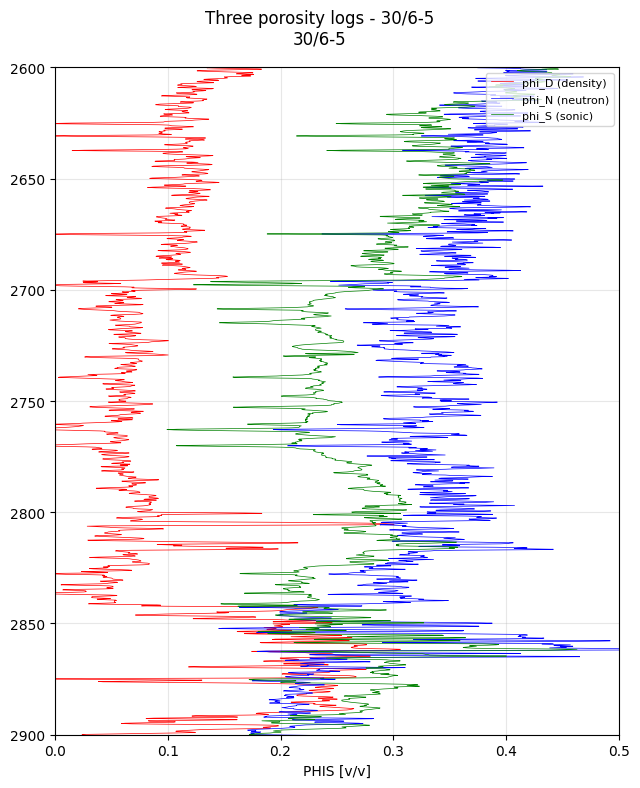

Window means: phi_D=0.105  phi_N=0.328  phi_S=0.278


In [6]:
from petrophys.visualization import LogPlot

top, base = 2600.0, 2900.0
sel = (depth >= top) & (depth <= base)

# Attach the computed porosity logs so LogPlot can render them.
well.add_curve('PHID', phid, unit='v/v', description='Density porosity')
well.add_curve('PHIS', phis, unit='v/v', description='Sonic porosity')

lp = LogPlot(well, figsize=(6.5, 8))
lp.create_figure(n_tracks=1)
lp.add_curve(0, 'PHID', color='red', xlim=(0, 0.5), label='phi_D (density)')
lp.add_curve(0, 'NPHI', color='blue', xlim=(0, 0.5), label='phi_N (neutron)')
lp.add_curve(0, 'PHIS', color='green', xlim=(0, 0.5), label='phi_S (sonic)')
lp.set_depth_range(top, base)
lp.add_title('Three porosity logs - 30/6-5')
lp.show()

print('Window means: phi_D=%.3f  phi_N=%.3f  phi_S=%.3f'
      % (np.nanmean(phid[sel]), np.nanmean(nphi[sel]), np.nanmean(phis[sel])))

### Where do they diverge? (gas vs shale)

We can flag the two regimes quantitatively. `detect_gas_effect` (in the total-porosity
module) marks samples where density porosity exceeds neutron by more than a threshold
- the gas signature.

To be honest about this well: 30/6-5 shows almost no real gas crossover (about 0.4%
of samples, only ~12 points in this window), so the HC-correction demo in Step 7
relies on the illustrative flat Sxo; the bundled well 25_5-1 carries a real crossover
cluster (~3018-3045 m) for readers who want a genuine example.

In [7]:
from petrophys.petrophysics.porosity.total_porosity import detect_gas_effect

gas_flag = detect_gas_effect(nphi, phid, threshold=0.05)
sep = phid - nphi   # positive -> density>neutron (gas-like); negative -> shale-like

finite = np.isfinite(sep)
print('Neutron-density separation (phi_D - phi_N):')
print('  gas-like  (phi_D > phi_N + 0.05): %6d samples (%.1f%%)'
      % (gas_flag[finite].sum(), 100.0 * gas_flag[finite].sum() / finite.sum()))
print('  shale-like(phi_N > phi_D)       : %6d samples (%.1f%%)'
      % ((sep < 0).sum(), 100.0 * (sep[finite] < 0).sum() / finite.sum()))
print()
print('Interpretation: gas-like points are candidate light-HC pay; strongly')
print('shale-like points (large negative separation) are clay-rich, low-quality rock.')

Neutron-density separation (phi_D - phi_N):
  gas-like  (phi_D > phi_N + 0.05):     74 samples (0.4%)
  shale-like(phi_N > phi_D)       :  16452 samples (94.5%)

Interpretation: gas-like points are candidate light-HC pay; strongly
shale-like points (large negative separation) are clay-rich, low-quality rock.


## Step 5 - Total porosity

`total_porosity(nphi, phi_d, method='adaptive')` combines neutron and density into a
single total porosity. The **adaptive** rule (default) is physically motivated:

- where **gas** is detected (phi_D > phi_N + 0.05), it trusts **density alone** (the
  neutron is suppressed by low hydrogen index);
- otherwise it uses the shale-tolerant weighted average $0.6\,\phi_D + 0.4\,\phi_N$.

Simpler `average` and `rms` methods are also available.

In [8]:
from petrophys.petrophysics.porosity import total_porosity

phit_adaptive = total_porosity(nphi, phid, method='adaptive')
phit_average  = total_porosity(nphi, phid, method='average')
phit_rms      = total_porosity(nphi, phid, method='rms')

print('Total porosity (whole well) by method:')
print('  adaptive : %.3f' % np.nanmean(phit_adaptive))
print('  average  : %.3f' % np.nanmean(phit_average))
print('  rms      : %.3f' % np.nanmean(phit_rms))

phit = phit_adaptive   # use adaptive downstream

Total porosity (whole well) by method:
  adaptive : 0.332
  average  : 0.315
  rms      : 0.330


## Step 6 - Effective porosity (reusing Vcl from notebook 03)

**Total** porosity includes clay-bound water, which is immovable and does not
contribute to flow. **Effective** porosity removes it:

$$ \phi_e = \phi_t - V_{cl}\cdot\phi_{clay} $$

where $\phi_{clay}$ is the porosity of pure clay (~0.15 by default). The library
clips the result to $[0,\ \min(\phi_t,\ 1-V_{cl})]$, so high-Vcl rock cannot go
negative. This is the
number that goes into net-pay and hydrocarbon volume calculations. We first rebuild
the Vcl curve exactly as in notebook 03, then call `effective_porosity`.

In [9]:
from petrophys.clay_volume import calculate_vcl
from petrophys.petrophysics.porosity import effective_porosity, calculate_phie

# Rebuild Vcl (notebook 03): neutron-density-primary combine, sandstone matrix.
vcl_res = calculate_vcl(well, gr_method='larionov_older', matrix='sandstone',
                        combine='auto')
vcl = vcl_res.vcl
print('Vcl (from notebook 03) mean : %.3f' % np.nanmean(vcl))

phie = effective_porosity(phit, vcl, phi_clay=0.15)
phie_alias = calculate_phie(phit, vcl, phi_clay=0.15)  # same thing
print('Total porosity     mean : %.3f' % np.nanmean(phit))
print('Effective porosity mean : %.3f' % np.nanmean(phie))
print('Clay-bound water   mean : %.3f v/v' % (np.nanmean(phit) - np.nanmean(phie)))

Vcl (from notebook 03) mean : 0.379
Total porosity     mean : 0.332
Effective porosity mean : 0.275
Clay-bound water   mean : 0.057 v/v


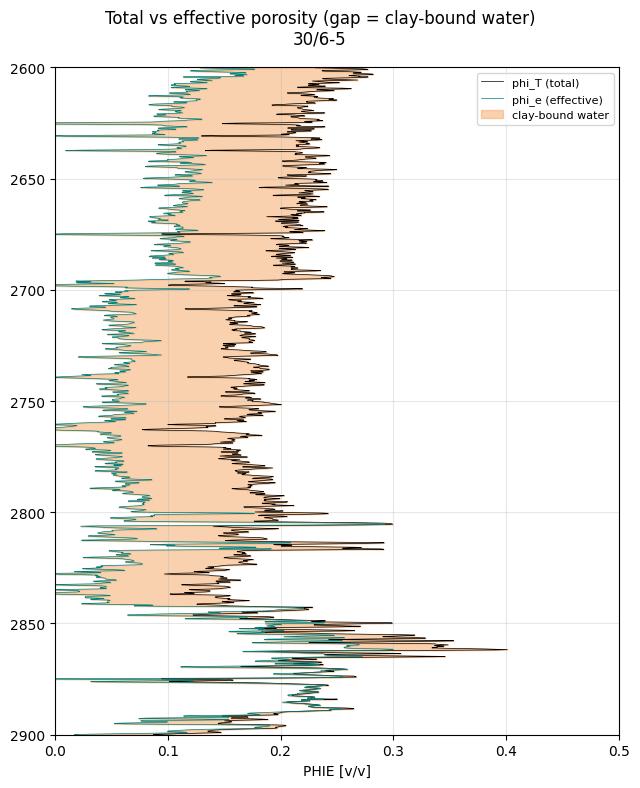

In [10]:
# Total vs effective vs clay, over the window, via the library LogPlot.
from petrophys.visualization import LogPlot

well.add_curve('PHIT', phit, unit='v/v', description='Total porosity')
well.add_curve('PHIE', phie, unit='v/v', description='Effective porosity')

lp = LogPlot(well, figsize=(6.5, 8))
lp.create_figure(n_tracks=1)
lp.add_curve(0, 'PHIT', color='black', xlim=(0, 0.5), label='phi_T (total)')
lp.add_curve(0, 'PHIE', color='teal', xlim=(0, 0.5), label='phi_e (effective)')
# Shade the clay-bound-water gap (phi_e -> phi_T) on the library axis.
lp.axes[0].fill_betweenx(depth[sel], phie[sel], phit[sel],
                         color='sandybrown', alpha=0.5, label='clay-bound water')
lp.axes[0].legend(fontsize=8, loc='upper right')
lp.set_depth_range(top, base)
lp.add_title('Total vs effective porosity (gap = clay-bound water)')
lp.show()

## Step 7 - Hydrocarbon correction

Light hydrocarbon (especially **gas**) has a low density and a low hydrogen index, so
it makes the density log read **too porous** and the neutron log read **too tight**.
Where gas is present we correct the raw logs before recomputing porosity.

`correct_density_hc` and `correct_neutron_hc` implement the design-doc corrections.
Both take a **flushed-zone water saturation** `sxo` and, when `vcl` is supplied, use a
volumetric (preliminary-porosity) inversion. We demonstrate a **gas** correction with
an illustrative `sxo = 0.5` in the flushed zone (in a real job Sxo comes from a
micro-resistivity model - see the saturation notebooks).

In [11]:
from petrophys.petrophysics.hc_correction import (correct_density_hc,
                                                    correct_neutron_hc,
                                                    apply_hc_correction)

sxo = np.full(well.n_samples, 0.5)   # illustrative flushed-zone Sw

rhob_hc = correct_density_hc(rhob, phid, sxo, rhob_fluid=1.0, hc_type='gas',
                             vcl=vcl, rho_ma=2.65, rho_cl=2.45)
nphi_hc = correct_neutron_hc(nphi, phid, sxo, hc_type='gas',
                             vcl=vcl, phi_cl=0.15)

print('RHOB : raw %.3f -> HC-corrected %.3f g/cc'
      % (np.nanmean(rhob), np.nanmean(rhob_hc)))
print('NPHI : raw %.3f -> HC-corrected %.3f v/v'
      % (np.nanmean(nphi), np.nanmean(nphi_hc)))

# Porosity recomputed from the corrected logs.
phid_hc = density_porosity(rhob_hc, 2.65, 1.0)
phit_hc = total_porosity(nphi_hc, phid_hc, method='adaptive')
print()
print('Total porosity : raw %.3f -> HC-corrected %.3f'
      % (np.nanmean(phit), np.nanmean(phit_hc)))
print('The gas correction raises apparent bulk density and lowers the density')
print('porosity, yet whole-well PHIT rises: the flat illustrative Sxo raises')
print('NPHI everywhere, and that increase outweighs the density-porosity drop')
print('in the 0.6/0.4 blend outside gas zones. A real job would apply the')
print('correction only in flagged gas zones.')

RHOB : raw 2.176 -> HC-corrected 2.254 g/cc
NPHI : raw 0.389 -> HC-corrected 0.563 v/v

Total porosity : raw 0.332 -> HC-corrected 0.345
The gas correction raises apparent bulk density and lowers the density
porosity, yet whole-well PHIT rises: the flat illustrative Sxo raises
NPHI everywhere, and that increase outweighs the density-porosity drop
in the 0.6/0.4 blend outside gas zones. A real job would apply the
correction only in flagged gas zones.


In [12]:
# The module wrapper does both curves in one call and can read SXO/VCL from the well.
hc = apply_hc_correction(well, hc_type='gas', sxo=sxo, vcl=vcl)
print('apply_hc_correction returned:')
print('  nphi_hc mean : %.3f' % np.nanmean(hc.nphi_hc))
print('  rhob_hc mean : %.3f' % np.nanmean(hc.rhob_hc))

apply_hc_correction returned:
  nphi_hc mean : 0.563
  rhob_hc mean : 2.254


## Step 8 - Classifying porosity

`classify_porosity` bins porosity into reservoir-quality categories:

- `EXCELLENT` : > 20%
- `GOOD`      : 12-20%
- `FAIR`      : 6-12%
- `POOR`      : <= 6%

We classify the **effective** porosity, since that is the flow-relevant number.

In [13]:
from petrophys.petrophysics.porosity import classify_porosity

labels = classify_porosity(phie)
label_str = np.array([str(x).split('.')[-1] if x is not None else 'NaN' for x in labels])

finite = np.isfinite(phie)
order = ['EXCELLENT', 'GOOD', 'FAIR', 'POOR']
cats, counts = np.unique(label_str[finite], return_counts=True)
lookup = dict(zip(cats, counts))
print('Effective-porosity reservoir-quality split (whole well):')
for c in order:
    n = int(lookup.get(c, 0))
    print('  %-10s : %6d samples (%.1f%%)' % (c, n, 100.0 * n / finite.sum()))

Effective-porosity reservoir-quality split (whole well):
  EXCELLENT  :  13813 samples (62.3%)
  GOOD       :   2609 samples (11.8%)
  FAIR       :   2484 samples (11.2%)
  POOR       :   3270 samples (14.7%)


## Pitfalls and parameter choices

- **Matrix density / slowness is the biggest lever.** Sandstone vs limestone shifts
  porosity by several units. Set it from lithology, PEF, or crossplots - never assume.
- **Standardize the neutron log** to the true matrix before comparing with density,
  or the pair will look artificially crossed-over or converged.
- **Gas crossover is signal, not noise.** The `adaptive` total-porosity rule and the
  HC correction both exploit it; do not "average it away".
- **Total vs effective.** Report effective porosity for pay and volumetrics; total
  porosity for saturation modelling (which needs the clay-bound water).
- **Sonic misses secondary porosity.** In vuggy / fractured rock, phi_S < phi_D; the
  difference estimates secondary porosity.
- **HC correction needs Sxo.** Here we used a flat illustrative value; in production
  it comes from a flushed-zone saturation model.

## Recap

- Built porosity three independent ways: **density** (`density_porosity`), **neutron**
  (raw plus `standardize_nphi`), and **sonic** (`sonic_porosity` / Wyllie).
- Overlaid them and read the divergences: neutron-density **crossover = gas**,
  neutron-over-density **= shale**.
- Combined neutron + density into **total porosity** (`total_porosity`, adaptive) and
  stripped clay-bound water into **effective porosity** (`effective_porosity`) using
  the Vcl from notebook 03.
- Applied a **gas HC correction** (`correct_density_hc`, `correct_neutron_hc`) and saw
  that a flat illustrative Sxo actually raises whole-well PHIT - the correction
  belongs only in flagged gas zones.
- Classified effective porosity into reservoir-quality bins (`classify_porosity`).

## Try it yourself

> **Exercise 1.** Recompute density porosity with `rhob_fluid=1.1` (brine) instead of
> 1.0. How many porosity units does the whole-well mean change, and why?
>
> **Exercise 2.** Set `hc_type='oil'` in the HC correction and compare the corrected
> RHOB against the `gas` case. Which fluid perturbs the logs more, and why?
>
> **Exercise 3.** Compute `secondary_porosity(phis, phit)` (from the sonic module) and
> plot it. Where in the well does sonic under-read total porosity?

## What's next

With porosity and clay volume in hand, the next foundation is **water saturation** -
turning resistivity into a hydrocarbon estimate. Continue with the **saturation**
notebooks (Archie and the shaly-sand models), which consume the effective porosity
and Vcl produced here.